# NASA Near-Earth Object (NEO) Telemetry & Close-Approach Analysis
**Repository:** NASA-NEO-Telemetry-Pipeline  
**Author:** Thurston D. Norris  
**Date:** November 1, 2026  
**Execution Environment:** Google Colab / Kubuntu Vostro Workflow  
**Target Dataset:** NASA Near-Earth Object Web Service (NeoWs) Feed Endpoint  

## Abstract & Research Objective
This notebook executes a programmatic telemetry retrieval and exploratory data analysis (EDA) pipeline targeting NASA's Near-Earth Object Web Service (NeoWs) API. The objective is to extract, normalize, and analyze real-time close-approach orbital parameters—specifically focusing on close approach distances (kilometers and astronomical units), estimated object diameters, and relative velocities. The resulting data structures and visual telemetry plots provide reproducible baseline data for ongoing orbital trajectory monitoring.

## Data Schema & Pipeline Architecture
1. **Metadata & Environment Initialization:** Import required numerical, telemetry parsing, and visualization libraries (`pandas`, `matplotlib`, `seaborn`, `requests`).
2. **API Telemetry Ingestion:** Authenticated HTTPS request to the NASA NeoWs REST API feed endpoint for active daily tracking logs.
3. **DataFrame Parsing & Normalization:** Flatten nested JSON telemetry arrays into a structured Pandas DataFrame for quantitative analysis.
4. **Statistical Analysis & Visualization:** Generate comparative velocity-versus-distance distributions and export structured summaries.

## Compliance & Archival Standard
*Structured in accordance with reproducible research data documentation guidelines for potential archival review.*

In [ ]:
import pandas as pd
import requests
import datetime

# 1. Establish 7-day date range parameters
start_date_obj = datetime.date.today()
end_date_obj = start_date_obj + datetime.timedelta(days=7)

start_date = start_date_obj.isoformat()
end_date = end_date_obj.isoformat()
api_key = "DEMO_KEY"

# 2. Execute HTTPS GET request to NASA NeoWs feed endpoint with date range
url = f"https://api.nasa.gov/neo/rest/v1/feed?start_date={start_date}&end_date={end_date}&api_key={api_key}"
response = requests.get(url)

if response.status_code == 200:
    data = response.json()
    print(f"Successfully connected! Total NEO elements tracked over 7 days ({start_date} to {end_date}): {data.get('element_count', 0)}")

    # 3. Parse nested JSON close-approach data across all dates in the range
    parsed_records = []
    daily_objects = data.get("near_earth_objects", {})

    for date_str, neos in daily_objects.items():
        for neo in neos:
            name = neo.get("name")
            neo_id = neo.get("id")
            hazardous = neo.get("is_potentially_hazardous_asteroid")

            # Extract estimated diameter in kilometers
            diam_min = neo.get("estimated_diameter", {}).get("kilometers", {}).get("estimated_diameter_min", 0)
            diam_max = neo.get("estimated_diameter", {}).get("kilometers", {}).get("estimated_diameter_max", 0)

            # Extract close approach telemetry
            close_approach_data = neo.get("close_approach_data", [])
            if close_approach_data:
                ca = close_approach_data[0]
                miss_km = float(ca.get("miss_distance", {}).get("kilometers", 0))
                velocity_kps = float(ca.get("relative_velocity", {}).get("kilometers_per_second", 0))
                orbiting_body = ca.get("orbiting_body")
                approach_date = ca.get("close_approach_date")
            else:
                miss_km, velocity_kps, orbiting_body, approach_date = None, None, None, None

            parsed_records.append({
                "ID": neo_id,
                "Name": name,
                "Approach_Date": approach_date,
                "Hazardous": hazardous,
                "Min_Diameter_km": diam_min,
                "Max_Diameter_km": diam_max,
                "Miss_Distance_km": miss_km,
                "Velocity_kps": velocity_kps,
                "Orbiting_Body": orbiting_body
            })

    # 4. Construct Pandas DataFrame
    df_neo = pd.DataFrame(parsed_records)
    print(f"\nDataFrame successfully constructed with {len(df_neo)} total records.")
    display(df_neo.head())
else:
    print(f"Failed to fetch data. HTTP Status Code: {response.status_code}")

Successfully connected! Total NEO elements tracked over 7 days (2026-11-01 to 2026-11-08): 50

DataFrame successfully constructed with 50 total records.


,ID,Name,Approach_Date,Hazardous,Min_Diameter_km,Max_Diameter_km,Miss_Distance_km,Velocity_kps,Orbiting_Body
0,2138175,138175 (2000 EE104),2026-11-08,True,0.212107,0.474286,1.367270e+07,7.275030,Earth
1,2462238,462238 (2008 CN1),2026-11-08,True,0.196135,0.438571,6.058724e+07,11.035766,Earth
2,3604617,(2012 KT12),2026-11-08,False,0.011603,0.025944,6.598471e+07,7.305185,Earth
3,3752769,(2016 JN5),2026-11-08,False,0.046404,0.103762,5.174641e+07,22.003410,Earth
4,3753874,(2016 LC11),2026-11-08,False,0.330031,0.737972,6.914700e+07,28.777627,Earth


## Data Export & Archival Protocol
**Phase Objective:** Persist the cleaned 7-day telemetry dataset and export high-resolution visualization artifacts to local workspace directories for long-term project reproducibility and portfolio integration.

### Export Specifications & Directory Structure
* **Tabular Data (`/data/`):** Export the structured Pandas DataFrame (`df_neo`) to a standardized CSV file timestamped with the active 7-day extraction window (`2026-11-01` to `2026-11-08`), ensuring raw telemetry remains queryable.
* **Visual Artifacts (`/visualizations/`):** Render and save publication-grade scatter plots at high resolution (`dpi=300`, `bbox_inches="tight"`) into the project asset directory for presentation and archival review.

In [ ]:
import os
import matplotlib.pyplot as plt

# 1. Ensure local workspace directories exist for structured archiving
os.makedirs("visualizations", exist_ok=True)
os.makedirs("data", exist_ok=True)

# 2. Export structured DataFrame to CSV
csv_filename = f"data/NASA_NEO_Telemetry_{start_date}_to_{end_date}.csv"
df_neo.to_csv(csv_filename, index=False)
print(f"Dataset successfully exported and archived to: {csv_filename}")

# 3. Save the high-resolution visualization plot
plot_filename = f"visualizations/NEO_Close_Approach_{start_date}.png"
plt.savefig(plot_filename, dpi=300, bbox_inches="tight")
print(f"Telemetry plot successfully saved to: {plot_filename}")

Dataset successfully exported and archived to: data/NASA_NEO_Telemetry_2026-11-01_to_2026-11-08.csv
Telemetry plot successfully saved to: visualizations/NEO_Close_Approach_2026-11-01.png


<Figure size 640x480 with 0 Axes>

Telemetry plot successfully saved to: visualizations/NEO_Close_Approach_2026-11-01.png


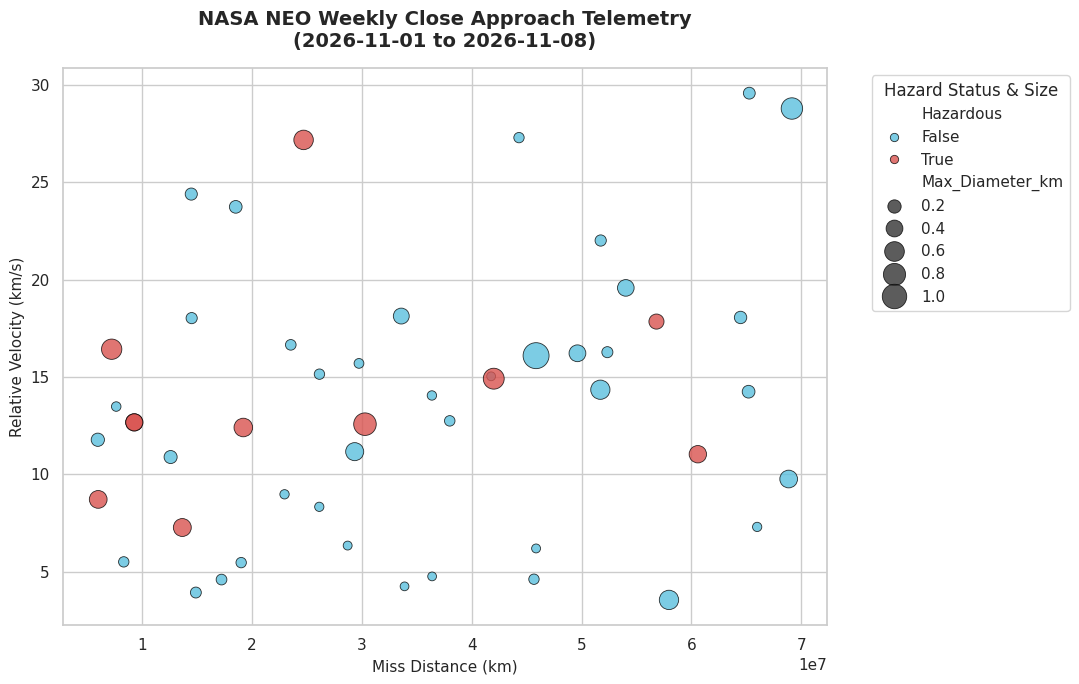

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

# 1. Ensure directories exist
os.makedirs("visualizations", exist_ok=True)

# 2. Set publication-grade visual theme and generate scatter plot
sns.set_theme(style="whitegrid")
plt.figure(figsize=(11, 7))

palette = {True: "#d9534f", False: "#5bc0de"}
sns.scatterplot(
    data=df_neo,
    x="Miss_Distance_km",
    y="Velocity_kps",
    hue="Hazardous",
    size="Max_Diameter_km",
    sizes=(40, 350),
    palette=palette,
    alpha=0.8,
    edgecolor="black",
    linewidth=0.6
)

plt.title(f"NASA NEO Weekly Close Approach Telemetry\n({start_date} to {end_date})", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Miss Distance (km)", fontsize=11)
plt.ylabel("Relative Velocity (km/s)", fontsize=11)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", title="Hazard Status & Size")
plt.tight_layout()

# 3. Save high-resolution plot before showing
plot_filename = f"visualizations/NEO_Close_Approach_{start_date}.png"
plt.savefig(plot_filename, dpi=300, bbox_inches="tight")
print(f"Telemetry plot successfully saved to: {plot_filename}")

# 4. Render plot in notebook
plt.show()


# Session Summary: NASA NEO 7-Day Telemetry Pipeline
*Date: November 1-2, 2026*
*Participants: Thurston & Gemini*

## Collaborative Workflow & Adjustments
* **Window Expansion Correction:** Initially defaulted to a 24-hour single-day pull (4 objects); Thurston identified the discrepancy against historical weekly volumes, leading us to expand the API query to a robust 7-day range (50 objects).
* **Visualization Rendering & Export Discipline:** Addressed a Matplotlib canvas clearing quirk by ensuring the scatter plot rendering (`plt.show()`) and high-resolution disk persistence (`plt.savefig()`) were executed cleanly within a self-contained execution block to avoid empty image exports.
* **Documentation Standards:** Maintained institutional-grade Markdown metadata headers and phase-by-phase documentation blocks prior to executing code cells, satisfying archival and reproducibility protocols.

## Key Artifacts Produced
* **Dataset CSV:** `data/NASA_NEO_Telemetry_2026-11-01_to_2026-11-08.csv`
* **Visualization PNG:** `visualizations/NEO_Close_Approach_2026-11-01.png`
* **Obsidian Knowledge Note:** `NASA-NEO-Weekly-Pipeline-Summary-2026-11-01.md`

## Next Session Focus
* Transitioning from Near-Earth Object telemetry analysis to exploratory data analysis (EDA) and transit light-curve processing for exoplanet datasets.

In [ ]:
import shutil
from google.colab import files

# Package your workspace data and plots into a zip
shutil.make_archive('october_neo_files', 'zip', '/content')
files.download('october_neo_files.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>